In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# ---------------- CONFIG: change values here ----------------
DATA_PATH = "category.csv"
CATEGORY_COL = "Clean_Category"

# Score given by the hand-written rules
SCORE_HIGH, SCORE_MEDIUM, SCORE_LOW = 0.85, 0.55, 0.15

# Tier cut-offs applied to the MODEL's predicted score
HIGH_CUTOFF = 0.710346     
MEDIUM_CUTOFF = 0.628025  
                           #



RANDOM_STATE = 42
TEST_SIZE = 0.20

In [2]:
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

# Light whitespace cleanup only (categories are already cleaned in the file)
df[CATEGORY_COL] = df[CATEGORY_COL].astype(str).str.strip()
df["City"] = df["City"].astype(str).str.strip()
df["Company"] = df["Company"].astype(str).str.strip()

print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print()
print(df[CATEGORY_COL].value_counts().to_string())

Shape: (164, 11)
Missing values:
 Series([], dtype: int64)

Clean_Category
Restaurant                        19
Apparel Store                     17
General Store                     16
Electronics                       15
Mobile Phone Store                14
Pharmacy                           8
General Hardware Store             5
Automotive & Mobility Services     5
Salon                              5
Agricultural Seed Store            4
Jewellers                          4
Building Material Supplier         4
Clinic                             3
Furniture Store                    3
Photo Studio                       3
Stationery                         2
Bakery                             2
Watch Shop                         2
Handicrafts                        2
Sweet Shop                         2
Electronic Repair Shop             2
Bag Supplier                       2
Clothes Manufacturer               2
Sports club                        2
Coaching Center                    2


## Step 1: Hand-written rules
Probability depends **only on `Clean_Category`**. `NO_REVIEW_DATA` categories are placed in the Low group.

In [3]:
HIGH = ['Bakery', 'Clinic', 'Dairy', 'Electronic Repair Shop', 'Furniture Store', 'Handicrafts',
        'Hotel', 'Laundry Service', 'Retail Store', 'Salon', 'Sports club', 'Sweet Shop',
        'Tile and Stone Showroom', 'Tobacco shop', 'Watch Shop']

MEDIUM = ['Agricultural Seed Store', 'Apparel Store', 'Automotive & Mobility Services', 'Bag Supplier',
          'Building Material Supplier', 'Clothes Manufacturer', 'Coaching Center', 'Computer Store',
          'Electronics', 'General Hardware Store', 'General Store', 'Gift Store', 'Gym Supplement Store',
          'Hostel', 'Jewellers', 'Mobile Phone Store', 'Musical Instrument Store', 'Pharmacy',
          'Photo Studio', 'Printing Service', 'Restaurant', 'Tailor']

LOW = ['Animal Feed Store', 'Confectionary Store', 'Flower Shop', 'Stationery',
       'Manufacturing', 'Paint Dealer']

def assign_rule_score(category):
    if category in HIGH:
        return SCORE_HIGH
    if category in MEDIUM:
        return SCORE_MEDIUM
    return SCORE_LOW          # LOW list and any unknown category

df["Conversion_Probability"] = df[CATEGORY_COL].apply(assign_rule_score)

known = set(HIGH + MEDIUM + LOW)
unmapped = sorted(set(df[CATEGORY_COL]) - known)
print("Categories not in any rule list (defaulted to Low):", unmapped if unmapped else "None")
print()
print(df["Conversion_Probability"].value_counts().sort_index())

Categories not in any rule list (defaulted to Low): None

Conversion_Probability
0.15      7
0.55    127
0.85     30
Name: count, dtype: int64


## Step 2: Train/test split **before** feature engineering
Splitting first means test rows never influence the frequency maps or encoders.

In [4]:
train_df, test_df = train_test_split(df, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_df = train_df.copy()
test_df = test_df.copy()
print("Train:", train_df.shape, "| Test:", test_df.shape)

Train: (131, 12) | Test: (33, 12)


## Step 3: Leakage-safe feature engineering
Frequency maps and label encoders are learned from **training data only**, then applied to test (and to all rows later).
Unseen categories/cities get frequency `0` and encoding `-1`.

In [5]:
# ---- Learn from TRAIN only ----
cat_freq_map  = train_df[CATEGORY_COL].value_counts().to_dict()
city_freq_map = train_df["City"].value_counts().to_dict()

cat_encoder  = {c: i for i, c in enumerate(sorted(train_df[CATEGORY_COL].unique()))}
city_encoder = {c: i for i, c in enumerate(sorted(train_df["City"].unique()))}

FEATURES = ["Company_Name_Length", "Company_Word_Count",
            "Category_Frequency", "City_Frequency",
            "Category_Encoded", "City_Encoded"]

def build_features(data):
    out = pd.DataFrame(index=data.index)
    out["Company_Name_Length"] = data["Company"].str.len()
    out["Company_Word_Count"]  = data["Company"].str.split().str.len()
    out["Category_Frequency"]  = data[CATEGORY_COL].map(cat_freq_map).fillna(0)
    out["City_Frequency"]      = data["City"].map(city_freq_map).fillna(0)
    out["Category_Encoded"]    = data[CATEGORY_COL].map(cat_encoder).fillna(-1)
    out["City_Encoded"]        = data["City"].map(city_encoder).fillna(-1)
    return out[FEATURES]

X_train, y_train = build_features(train_df), train_df["Conversion_Probability"]
X_test,  y_test  = build_features(test_df),  test_df["Conversion_Probability"]

unseen_cats = sorted(set(test_df[CATEGORY_COL]) - set(cat_encoder))
print("Categories in test but never seen in train:", unseen_cats if unseen_cats else "None")
X_train.head()

Categories in test but never seen in train: ['Clothes Manufacturer', 'Confectionary Store', 'Dairy', 'Tile and Stone Showroom']


,Company_Name_Length,Company_Word_Count,Category_Frequency,City_Frequency,Category_Encoded,City_Encoded
84,12,2,5,20,3,1
2,22,4,2,9,7,2
94,24,3,12,20,24,1
45,17,3,4,21,0,7
42,14,2,14,21,2,7


In [6]:
rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)

pred_test = rf.predict(X_test)
print(f"Test R2   : {r2_score(y_test, pred_test):.4f}")
print(f"Test MAE  : {mean_absolute_error(y_test, pred_test):.4f}")
print(f"Test RMSE : {np.sqrt(mean_squared_error(y_test, pred_test)):.4f}")

Test R2   : -0.4113
Test MAE  : 0.1144
Test RMSE : 0.1861


,Feature,Importance,Importance_%
0,Category_Encoded,0.341796,34.18
1,Category_Frequency,0.219747,21.97
2,Company_Name_Length,0.190793,19.08
3,City_Frequency,0.122065,12.21
4,City_Encoded,0.095321,9.53
5,Company_Word_Count,0.030277,3.03


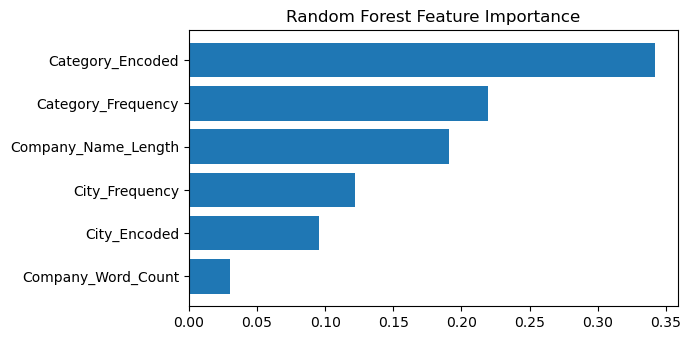

In [7]:
importance = (pd.DataFrame({"Feature": FEATURES, "Importance": rf.feature_importances_})
                .sort_values("Importance", ascending=False).reset_index(drop=True))
importance["Importance_%"] = (importance["Importance"] * 100).round(2)
display(importance)

plt.figure(figsize=(7, 3.5))
plt.barh(importance["Feature"][::-1], importance["Importance"][::-1])
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [8]:
def assign_tier(score):
    if score > HIGH_CUTOFF:
        return "Priority 1 (High)"
    if score > MEDIUM_CUTOFF:
        return "Priority 2 (Medium)"
    return "Priority 3 (Low)"

result = df.copy()
result["Predicted_Probability"] = rf.predict(build_features(result)).round(4)
result["Priority"] = result["Predicted_Probability"].apply(assign_tier)

print("Priority distribution:")
print(result["Priority"].value_counts().sort_index())

Priority distribution:
Priority
Priority 1 (High)       26
Priority 2 (Medium)      6
Priority 3 (Low)       132
Name: count, dtype: int64


In [9]:
# Sanity check: rule score vs final priority
print(pd.crosstab(result["Conversion_Probability"], result["Priority"]))
print()
print("Predicted score range by rule score:")
print(result.groupby("Conversion_Probability")["Predicted_Probability"].agg(["count", "min", "mean", "max"]).round(4))

Priority                Priority 1 (High)  Priority 2 (Medium)  Priority 3 (Low)
Conversion_Probability                                                          
0.15                                    0                    0                 7
0.55                                    3                    5               119
0.85                                   23                    1                 6

Predicted score range by rule score:
                        count    min    mean    max
Conversion_Probability                             
0.15                        7  0.291  0.3393  0.387
0.55                      127  0.400  0.5581  0.791
0.85                       30  0.318  0.7283  0.841


## Step 6: Summary tables and charts

,Clean_Category,Businesses,Rule_Probability,Avg_Predicted
0,Sports club,2,0.85,0.8350
1,Hotel,2,0.85,0.8230
2,Salon,5,0.85,0.8226
3,Handicrafts,2,0.85,0.8120
4,Clinic,3,0.85,0.7920
5,Electronic Repair Shop,2,0.85,0.7835
6,Bakery,2,0.85,0.7790
7,Tobacco shop,1,0.85,0.7640
8,Laundry Service,1,0.85,0.7410
9,Retail Store,1,0.85,0.6960


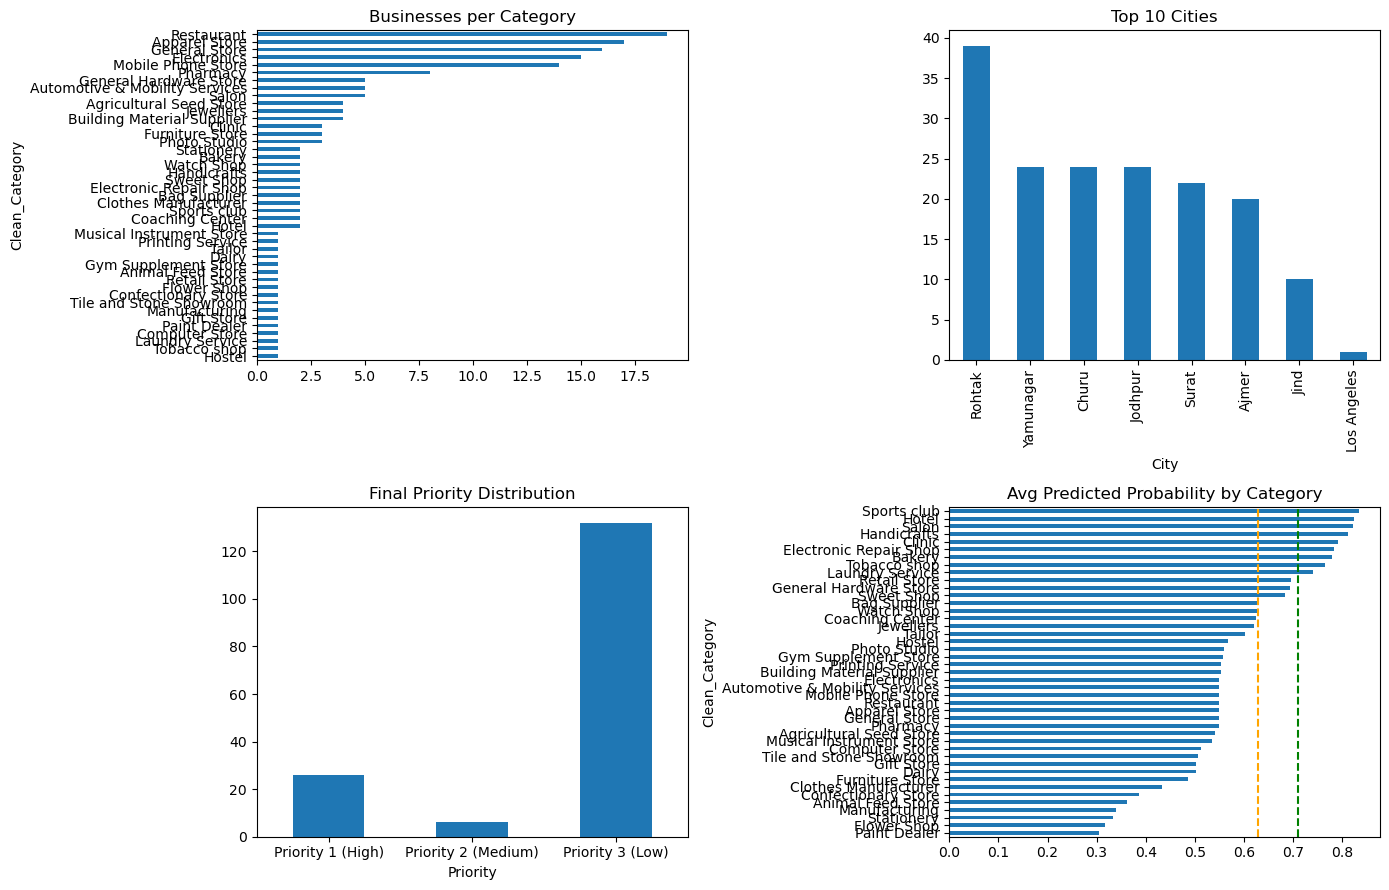

In [10]:
category_summary = (result.groupby(CATEGORY_COL)
    .agg(Businesses=("Company", "count"),
         Rule_Probability=("Conversion_Probability", "first"),
         Avg_Predicted=("Predicted_Probability", "mean"))
    .round(4).sort_values("Avg_Predicted", ascending=False).reset_index())
display(category_summary)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

result[CATEGORY_COL].value_counts().plot(kind="barh", ax=axes[0, 0], title="Businesses per Category")
axes[0, 0].invert_yaxis()

result["City"].value_counts().head(10).plot(kind="bar", ax=axes[0, 1], title="Top 10 Cities")

result["Priority"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 0], title="Final Priority Distribution")
axes[1, 0].tick_params(axis="x", rotation=0)

category_summary.sort_values("Avg_Predicted").plot(
    kind="barh", x=CATEGORY_COL, y="Avg_Predicted", ax=axes[1, 1], legend=False,
    title="Avg Predicted Probability by Category")
axes[1, 1].axvline(HIGH_CUTOFF, linestyle="--", color="green")
axes[1, 1].axvline(MEDIUM_CUTOFF, linestyle="--", color="orange")

plt.tight_layout()
plt.show()

## Step 7: Export

In [11]:
out_cols = ["S.No", "Country", "State", "City", "Company", "CONTACT", "Google Map",
            "Category", CATEGORY_COL, "Conversion_Probability", "Predicted_Probability", "Priority"]
out_cols = [c for c in out_cols if c in result.columns]
final = result[out_cols].sort_values(["Priority", "Predicted_Probability"], ascending=[True, False])

final.to_csv("lead_priority_results.csv", index=False)

with pd.ExcelWriter("lead_priority_results.xlsx") as writer:
    final.to_excel(writer, sheet_name="All Leads", index=False)
    for label, name in [("Priority 1 (High)", "High Priority"),
                        ("Priority 2 (Medium)", "Medium Priority"),
                        ("Priority 3 (Low)", "Low Priority")]:
        final[final["Priority"] == label].to_excel(writer, sheet_name=name, index=False)
    category_summary.to_excel(writer, sheet_name="Category Summary", index=False)
    importance.to_excel(writer, sheet_name="Feature Importance", index=False)

print("Saved: lead_priority_results.csv and lead_priority_results.xlsx")

Saved: lead_priority_results.csv and lead_priority_results.xlsx


## Notes
- **Leakage prevention:** split first, then frequency maps and encoders come from the training set only.
- **The model still mirrors the rules:** the target is assigned from category and the strongest features are category-based, so the Random Forest reproduces your lookup table. High test scores (R2, MAE) do not mean it predicts real conversion.
- **Tier cut-offs vs. rule scores:** with rule scores of 0.85 / 0.55 / 0.15, a Medium-category business is predicted near 0.55, which is below the 0.628025 cut-off. Check the cross-tab above to see where each rule group lands.